AdaboostClassifier -- similarly regressor

In [29]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,r2_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import AdaBoostClassifier
from tqdm import tqdm
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import make_column_transformer, make_column_selector
import warnings
warnings.filterwarnings("ignore")

In [30]:
df=pd.read_csv(r"E:\DataAnalytics\Cases\Wisconsin\BreastCancer.csv",index_col=0)
df.head()

,Clump,UniCell_Size,Uni_CellShape,MargAdh,SEpith,BareN,BChromatin,NoemN,Mitoses,Class
Code,,,,,,,,,,
61634,5,4,3,1,2,2,2,3,1,Benign
63375,9,1,2,6,4,10,7,7,2,Malignant
76389,10,4,7,2,2,8,6,1,1,Malignant
95719,6,10,10,10,8,10,7,10,7,Malignant
128059,1,1,1,1,2,5,5,1,1,Benign


In [31]:
X,y=df.drop('Class',axis=1),df['Class']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=26,stratify=y)

In [32]:
lr=LogisticRegression()
dtc=DecisionTreeClassifier(random_state=26,max_depth=1)# bydefault Estimator for the adaboost

In [33]:
model=AdaBoostClassifier(estimator=dtc,n_estimators=10,random_state=26)
model.fit(X_train,y_train)

,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",DecisionTreeC...ndom_state=26)
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",26
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[object](2,)","['Benign','Malignant']"
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeClassifier,DecisionTreeC...ndom_state=26)
estimator_errors_ estimator_errors_: ndarray of floatsClassification error for each estimator in the boostedensemble.,"ndarray[float64](10,)","[0.07,0.16,0.19,...,0.35,0.39,0.41]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](10,)","[2.66,1.65,1.44,...,0.61,0.46,0.37]"
estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators.,list,"[DecisionTreeC...te=1322570549), DecisionTreeC...ate=915305790), DecisionTreeC...tate=83285766), DecisionTreeC...te=1266656688), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](9,)","[0.18,0. ,0.34,...,0. ,0.09,0. ]"


In [34]:
y_pred=model.predict(X_test)
accuracy_score(y_test,y_pred)

0.9428571428571428

In [35]:
model=AdaBoostClassifier(estimator=lr,n_estimators=10,random_state=26)
model.fit(X_train,y_train)

,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",LogisticRegression()
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",26
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[object](2,)","['Benign','Malignant']"
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,LogisticRegression,LogisticRegression()
estimator_errors_ estimator_errors_: ndarray of floatsClassification error for each estimator in the boostedensemble.,"ndarray[float64](10,)","[0.04,0.28,0.38,...,1. ,1. ,1. ]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](10,)","[3.06,0.94,0.47,...,0. ,0. ,0. ]"
estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators.,list,"[LogisticRegre...te=1322570549), LogisticRegre...ate=915305790), LogisticRegre...tate=83285766), LogisticRegre...te=1266656688), ...]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](9,)","['Clump','UniCell_Size','Uni_CellShape',...,'BChromatin','NoemN','Mitoses']"


In [36]:
y_pred=model.predict(X_test)
accuracy_score(y_test,y_pred)

0.9714285714285714

# AdaBoostRegressor

In [37]:
from sklearn.ensemble import AdaBoostRegressor
from sklearn.linear_model import LinearRegression,Lasso


Gradiant boosting Classifier 

In [38]:
from sklearn.ensemble import GradientBoostingClassifier 

In [39]:
gbm=GradientBoostingClassifier(random_state=26)
gbm.fit(X_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",26
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

In [40]:
y_pred=gbm.predict(X_test)
accuracy_score(y_test,y_pred)

0.9571428571428572

# GradientBoostingRegressor

In [41]:
from sklearn.ensemble import GradientBoostingRegressor 

In [42]:
df=pd.read_csv(r"E:\DataAnalytics\Cases\Concrete_Strength\Concrete_Data.csv")
df.head()

,Cement,Blast,Fly,Water,Superplasticizer,Coarse,Fine,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [43]:
X,y=df.drop('Strength',axis=1),df['Strength']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=26)

In [44]:
gbr=GradientBoostingRegressor(random_state=26)

In [45]:
gbr.fit(X_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",26
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf

In [46]:
y_pred=gbr.predict(X_test)
r2_score(y_test,y_pred)

0.8997023518625237

In [47]:
learning_rate=np.linspace(0.1,0.9,10)
max_depth=[None,2,3,4]
n_estimators=[25,50,100]
scores=[]

for l in tqdm(learning_rate):
    for m in max_depth:
        for n in n_estimators:
            gbr=GradientBoostingRegressor(random_state=26,learning_rate=l,max_depth=m,n_estimators=n)
            gbr.fit(X_train,y_train)
            y_pred=gbr.predict(X_test)
            scores.append([l,m,n,r2_score(y_test,y_pred)])
df_scores=pd.DataFrame(scores,columns=['Learning_Rate','Max_Depth','N_Estimators','R2_Score'])
df_scores.sort_values(by='R2_Score',ascending =False)

100%|██████████| 10/10 [00:14<00:00,  1.46s/it]


,Learning_Rate,Max_Depth,N_Estimators,R2_Score
80,0.633333,3.0,100,0.932455
47,0.366667,4.0,100,0.928307
101,0.811111,2.0,100,0.927306
79,0.633333,3.0,50,0.926332
56,0.455556,3.0,100,0.925730
...,...,...,...,...
37,0.366667,NaN,50,0.833627
4,0.100000,2.0,50,0.828871
15,0.188889,2.0,25,0.826759
6,0.100000,3.0,25,0.802354


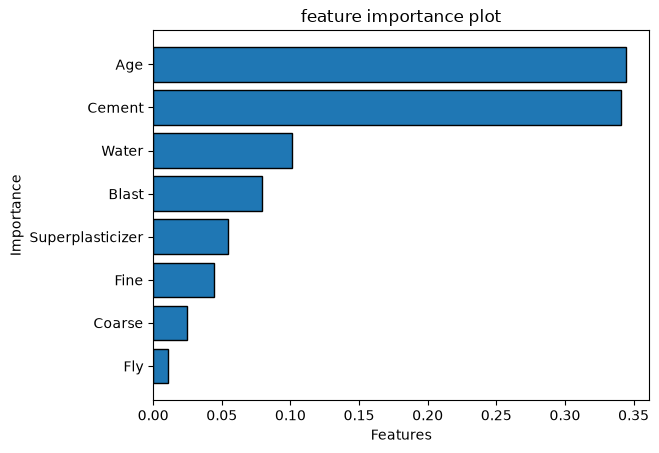

In [48]:
best_tree=GradientBoostingRegressor(random_state=26,learning_rate=0.633333,max_depth=3,n_estimators=100)
best_tree.fit(X, y)
df_imp= pd.DataFrame({'features': list(X.columns), 'importance':best_tree.feature_importances_})
df_imp.sort_values('importance', inplace= True)
plt.barh(df_imp['features'], df_imp['importance'],edgecolor='black')
plt.title('feature importance plot')
plt.xlabel('Features')
plt.ylabel('Importance')
plt.show()

## --XGBoost

In [58]:
from xgboost import XGBClassifier

In [59]:
df=pd.read_csv(r"E:\DataAnalytics\Cases\human-resources-analytics\HR_comma_sep.csv")
df.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.10,0.77,6,247,4,0,1,0,sales,low
3,0.92,0.85,5,259,5,0,1,0,sales,low
4,0.89,1.00,5,224,5,0,1,0,sales,low


In [60]:
X,y=df.drop('left',axis=1),df['left']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=26,stratify=y)

In [61]:
ohe=OneHotEncoder(sparse_output=False,drop='first').set_output(transform='pandas')
ct=make_column_transformer(
    (ohe,make_column_selector(dtype_include='object')),
    ('passthrough',make_column_selector(dtype_include='number')),
    verbose_feature_names_out=False
).set_output(transform='pandas')
X_train=ct.fit_transform(X_train)
X_test=ct.transform(X_test)

In [63]:
learning_rate=np.linspace(0.1,0.9,10)
max_depth=[None,2,3,4]
n_estimators=[25,50,100]
scores=[]

for l in tqdm(learning_rate):
    for m in max_depth:
        for n in n_estimators:
            xgb=XGBClassifier(random_state=26,learning_rate=l,max_depth=m,n_estimators=n)
            xgb.fit(X_train,y_train)
            y_pred=xgb.predict(X_test)
            scores.append([l,m,n,accuracy_score(y_test,y_pred)])
df_scores=pd.DataFrame(scores,columns=['Learning_Rate','Max_Depth','N_Estimators','Accuracy_score'])
df_scores.sort_values(by='Accuracy_score',ascending =False)

100%|██████████| 10/10 [00:17<00:00,  1.72s/it]


,Learning_Rate,Max_Depth,N_Estimators,Accuracy_score
61,0.544444,NaN,50,0.987997
62,0.544444,NaN,100,0.987997
50,0.455556,NaN,100,0.987775
109,0.900000,NaN,50,0.987553
73,0.633333,NaN,50,0.987331
...,...,...,...,...
16,0.188889,2.0,50,0.968882
27,0.277778,2.0,25,0.965992
4,0.100000,2.0,50,0.957102
15,0.188889,2.0,25,0.956435


### Xgboost is comparatively faster and efficient than sklearns GradiantBoosting

In [64]:
learning_rate=np.linspace(0.1,0.9,10)
max_depth=[None,2,3,4]
n_estimators=[25,50,100]
scores=[]

for l in tqdm(learning_rate):
    for m in max_depth:
        for n in n_estimators:
            gbc=GradientBoostingClassifier(random_state=26,learning_rate=l,max_depth=m,n_estimators=n)
            gbc.fit(X_train,y_train)
            y_pred=gbc.predict(X_test)
            scores.append([l,m,n,accuracy_score(y_test,y_pred)])
df_scores=pd.DataFrame(scores,columns=['Learning_Rate','Max_Depth','N_Estimators','Accuracy_score'])
df_scores.sort_values(by='Accuracy_score',ascending =False)

100%|██████████| 10/10 [01:49<00:00, 10.98s/it]


,Learning_Rate,Max_Depth,N_Estimators,Accuracy_score
107,0.811111,4.0,100,0.985775
71,0.544444,4.0,100,0.984886
106,0.811111,4.0,50,0.984219
59,0.455556,4.0,100,0.983552
83,0.633333,4.0,100,0.982885
...,...,...,...,...
4,0.100000,2.0,50,0.956212
15,0.188889,2.0,25,0.949767
118,0.900000,4.0,50,0.910425
3,0.100000,2.0,25,0.907535


## ---Liter version of gradient boost  

In [106]:
from lightgbm import LGBMClassifier #here the verbose takes the integer parameter so we have to be vary to not give false

In [70]:
learning_rate=np.linspace(0.1,0.9,10)
max_depth=[None,2,3,4]
n_estimators=[25,50,100]
scores=[]

for l in tqdm(learning_rate):
    for m in max_depth:
        for n in n_estimators:
            lgbmc=LGBMClassifier(random_state=26,learning_rate=l,max_depth=m,n_estimators=n,verbose=-1)
            lgbmc.fit(X_train,y_train)
            y_pred=lgbmc.predict(X_test)
            scores.append([l,m,n,accuracy_score(y_test,y_pred)])
df_scores=pd.DataFrame(scores,columns=['Learning_Rate','Max_Depth','N_Estimators','Accuracy_score'])
df_scores.sort_values(by='Accuracy_score',ascending =False)

100%|██████████| 10/10 [00:04<00:00,  2.00it/s]


,Learning_Rate,Max_Depth,N_Estimators,Accuracy_score
38,0.366667,NaN,100,0.989331
26,0.277778,NaN,100,0.989331
37,0.366667,NaN,50,0.988664
62,0.544444,NaN,100,0.988664
61,0.544444,NaN,50,0.988664
...,...,...,...,...
3,0.100000,2.0,25,0.911314
119,0.900000,4.0,100,0.908424
110,0.900000,NaN,100,0.825517
86,0.722222,NaN,100,0.786397


## catboosting 

In [72]:
from catboost import CatBoostClassifier

In [75]:
learning_rate=np.linspace(0.1,0.9,10)
max_depth=[None,2,3,4]
n_estimators=[25,50,100]
scores=[]

for l in tqdm(learning_rate):
    for m in max_depth:
        for n in n_estimators:
            cbc=CatBoostClassifier(random_state=26,learning_rate=l,max_depth=m,n_estimators=n,verbose=False)
            cbc.fit(X_train,y_train)
            y_pred=cbc.predict(X_test)
            scores.append([l,m,n,accuracy_score(y_test,y_pred)])
df_scores=pd.DataFrame(scores,columns=['Learning_Rate','Max_Depth','N_Estimators','Accuracy_score'])
df_scores.sort_values(by='Accuracy_score',ascending =False)

100%|██████████| 10/10 [00:35<00:00,  3.54s/it]


,Learning_Rate,Max_Depth,N_Estimators,Accuracy_score
98,0.811111,NaN,100,0.981551
74,0.633333,NaN,100,0.981329
110,0.900000,NaN,100,0.980440
86,0.722222,NaN,100,0.979773
107,0.811111,4.0,100,0.979773
...,...,...,...,...
6,0.100000,3.0,25,0.963992
4,0.100000,2.0,50,0.960658
15,0.188889,2.0,25,0.960213
27,0.277778,2.0,25,0.957991


In [80]:
X,y=df.drop('left',axis=1),df['left']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=26,stratify=y)

In [81]:
# Without encoding the catogerical Features 
categories=['Department','salary']
#it do not perform encoding internally so performence Varies due to this Feature
cbc=CatBoostClassifier(random_state=26,learning_rate=0.811111,n_estimators=100,verbose=False,cat_features=categories)
cbc.fit(X_train,y_train)

CatBoostClassifier(cat_features=['Department', 'salary'], learning_rate=0.811111, n_estimators=100, random_state=26, verbose=False)

In [82]:
y_pred=cbc.predict(X_test)
accuracy_score(y_test,y_pred)

0.9806623694154256

In [84]:
learning_rate=np.linspace(0.1,0.9,10)
max_depth=[None,2,3,4]
n_estimators=[25,50,100]
scores=[]

for l in tqdm(learning_rate):
    for m in max_depth:
        for n in n_estimators:
            cbc=CatBoostClassifier(random_state=26,learning_rate=l,max_depth=m,n_estimators=n,verbose=False,cat_features=categories)
            cbc.fit(X_train,y_train)
            y_pred=cbc.predict(X_test)
            scores.append([l,m,n,accuracy_score(y_test,y_pred)])
df_scores=pd.DataFrame(scores,columns=['Learning_Rate','Max_Depth','N_Estimators','Accuracy_score'])
df_scores.sort_values(by='Accuracy_score',ascending =False)

100%|██████████| 10/10 [02:09<00:00, 12.94s/it]


,Learning_Rate,Max_Depth,N_Estimators,Accuracy_score
110,0.900000,NaN,100,0.980885
98,0.811111,NaN,100,0.980662
86,0.722222,NaN,100,0.979329
74,0.633333,NaN,100,0.978217
50,0.455556,NaN,100,0.977995
...,...,...,...,...
27,0.277778,2.0,25,0.964659
39,0.366667,2.0,25,0.964214
15,0.188889,2.0,25,0.956879
4,0.100000,2.0,50,0.955323


# Exercise on vehicle dataset

In [86]:
df=pd.read_csv(r"E:\DataAnalytics\Cases\Vehicle Silhouettes\Vehicle.csv")
df.head()

,Comp,Circ,D.Circ,Rad.Ra,Pr.Axis.Ra,Max.L.Ra,Scat.Ra,Elong,Pr.Axis.Rect,Max.L.Rect,Sc.Var.Maxis,Sc.Var.maxis,Ra.Gyr,Skew.Maxis,Skew.maxis,Kurt.maxis,Kurt.Maxis,Holl.Ra,Class
0,95,48,83,178,72,10,162,42,20,159,176,379,184,70,6,16,187,197,van
1,91,41,84,141,57,9,149,45,19,143,170,330,158,72,9,14,189,199,van
2,104,50,106,209,66,10,207,32,23,158,223,635,220,73,14,9,188,196,saab
3,93,41,82,159,63,9,144,46,19,143,160,309,127,63,6,10,199,207,van
4,85,44,70,205,103,52,149,45,19,144,241,325,188,127,9,11,180,183,bus


In [92]:
from sklearn.preprocessing import LabelEncoder

In [93]:
X,y=df.drop('Class',axis=1),df['Class']
le = LabelEncoder()
y_encoded = le.fit_transform(y)
X_train,X_test,y_train,y_test=train_test_split(X,y_encoded,test_size=0.3,random_state=26,stratify=y)

In [ ]:
boosting_techniques=[GradientBoostingClassifier,XGBClassifier,LGBMClassifier,CatBoostClassifier]
learning_rate=np.linspace(0.1,0.9,10)
max_depth=[None,2,3,4]
n_estimators=[25,50,100]
scores=[]
for boost in tqdm(boosting_techniques):
    for l in learning_rate:
        for m in max_depth:
            for n in n_estimators:
                model=boost(random_state=26,learning_rate=l,max_depth=m,n_estimators=n)
                model.fit(X_train,y_train)
                y_pred=model.predict(X_test)
                scores.append([boost.__name__,l,m,n,accuracy_score(y_test,y_pred)])
df_scores=pd.DataFrame(scores,columns=['Boosting_algorithm','Learning_Rate','Max_Depth','N_Estimators','Accuracy_Score'])
df_scores.sort_values(by='Accuracy_Score',ascending =False)

In [107]:
df_scores.sort_values(by='Accuracy_Score',ascending =False)

,Boosting_algorithm,Learning_Rate,Max_Depth,N_Estimators,Accuracy_Score
269,LGBMClassifier,0.277778,2.0,100,0.807087
342,LGBMClassifier,0.811111,3.0,25,0.803150
307,LGBMClassifier,0.544444,3.0,50,0.803150
340,LGBMClassifier,0.811111,2.0,50,0.799213
281,LGBMClassifier,0.366667,2.0,100,0.795276
...,...,...,...,...,...
85,GradientBoostingClassifier,0.722222,NaN,50,0.696850
375,CatBoostClassifier,0.188889,2.0,25,0.692913
24,GradientBoostingClassifier,0.277778,NaN,25,0.692913
123,XGBClassifier,0.100000,2.0,25,0.688976


In [129]:
pd.DataFrame(df_scores.groupby('Boosting_algorithm')['Accuracy_Score'].max()).sort_values(by='Accuracy_Score')

KeyError: 'Column not found: Accuracy_Score'

In [113]:
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

In [116]:
df=pd.read_csv(r"E:\DataAnalytics\Cases\Medical_Cost_Personal\insurance.csv")
df.head()


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [117]:
X,y=df.drop('charges',axis=1),df['charges']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=26)


In [118]:
ohe=OneHotEncoder(sparse_output=False,drop='first').set_output(transform='pandas')
ct=make_column_transformer(
    (ohe,make_column_selector(dtype_include='object')),
    ('passthrough',make_column_selector(dtype_include='number')),
    verbose_feature_names_out=False
).set_output(transform='pandas')
X_train=ct.fit_transform(X_train)
X_test=ct.transform(X_test)

In [ ]:
boosting_techniques=[GradientBoostingRegressor,XGBRegressor,LGBMRegressor,CatBoostRegressor]
learning_rate=np.linspace(0.1,0.9,10)
max_depth=[None,2,3,4]
n_estimators=[25,50,100]
scores=[]
for boost in tqdm(boosting_techniques):
    for l in learning_rate:
        for m in max_depth:
            for n in n_estimators:
                model=boost(random_state=26,learning_rate=l,max_depth=m,n_estimators=n)
                model.fit(X_train,y_train)
                y_pred=model.predict(X_test)
                scores.append([boost.__name__,l,m,n,r2_score(y_test,y_pred)])
df_scores=pd.DataFrame(scores,columns=['Boosting_algorithm','Learning_Rate','Max_Depth','N_Estimators','R2_Score'])
df_scores.sort_values(by='R2_Score',ascending =False)

In [121]:
df_scores.sort_values(by='R2_Score',ascending =False)

,Boosting_algorithm,Learning_Rate,Max_Depth,N_Estimators,R2_Score
403,CatBoostRegressor,0.366667,3.0,50,0.875162
402,CatBoostRegressor,0.366667,3.0,25,0.875095
379,CatBoostRegressor,0.188889,3.0,50,0.874736
380,CatBoostRegressor,0.188889,3.0,100,0.873482
128,XGBRegressor,0.100000,3.0,100,0.873379
...,...,...,...,...,...
98,GradientBoostingRegressor,0.811111,NaN,100,0.777883
96,GradientBoostingRegressor,0.811111,NaN,25,0.777883
108,GradientBoostingRegressor,0.900000,NaN,25,0.775441
110,GradientBoostingRegressor,0.900000,NaN,100,0.775441


In [128]:
pd.DataFrame(df_scores.groupby('Boosting_algorithm')['R2_Score'].max()).sort_values(by='R2_Score')

,R2_Score
Boosting_algorithm,
GradientBoostingRegressor,0.870146
LGBMRegressor,0.871497
XGBRegressor,0.873379
CatBoostRegressor,0.875162
